## 1) Import Libraries

In [3]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import IsolationForest, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, r2_score, mean_absolute_error)
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_predict
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# 
CANDIDATE_PATHS = [Path("data.xlsx"), Path("/mnt/user-data/uploads/data.xlsx"),
                   Path(r"C:\Users\Notebook\Downloads\data.xlsx")]
DATA_PATH = next((p for p in CANDIDATE_PATHS if p.exists()), None)
assert DATA_PATH is not None, "فایل data.xlsx پیدا نشد؛ آن را کنار نوت‌بوک بگذارید یا CANDIDATE_PATHS را ویرایش کنید."
OUTPUT_DIR = Path("outputs"); OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
CONTAMINATION = 0.02         
IMPORT_LABEL = "وارداتی"


COLS = {
 "IRC":"irc", "کد ژنریک":"generic_code", "نام ژنریک":"generic", "نام لاتین فهرست":"inn", "کد ATC":"atc",
 "نام شرکت پخش":"distributor", "نام لاتین برند":"brand_en", "نام برند":"brand",
 "(تعداد فروش(بسته":"packs", "فروش عددی":"units",
 "فروش ریالی ( مبتنی بر قیمت فروش به پخش)":"rev_supplier",
 "فروش ریالی ( مبتنی بر قیمت فروش به داروخانه)":"rev_pharmacy",
 "فروش ریالی ( مبتنی بر قیمت فروش به مصرف کننده)":"revenue",
 "قیمت تامین کننده به پخش (ریال)":"p_supplier", "قیمت پخش به داروخانه (ریال)":"p_pharmacy",
 "قیمت فروش به مصرف کننده (ریال)":"p_consumer", "تعداد در بسته":"pack_size",
 "نام شرکت تامین کننده":"supplier", "صاحب نام تجاری":"brand_owner", "شرکت تولید کننده":"manufacturer",
 "کشور صاحب نام تجاری":"country", "OTC":"otc", "بیولوژیک":"biologic", "تحت لیسانس":"licensed",
 "تولیدی/وارداتی":"origin", "ثبتی/فوریتی":"reg_type"}

ATC1_NAMES = {"A":"Alimentary/Metabolism","B":"Blood","C":"Cardiovascular","D":"Dermatologicals","G":"Genito-urinary/Sex hormones",
              "H":"Systemic hormones","J":"Anti-infectives","L":"Antineoplastic/Immuno","M":"Musculo-skeletal","N":"Nervous system",
              "P":"Antiparasitic","R":"Respiratory","S":"Sensory organs","V":"Various","U":"Unknown"}

def savefig(name):
    plt.tight_layout(); plt.savefig(OUTPUT_DIR / name, dpi=200, bbox_inches="tight"); plt.show()

raw = pd.read_excel(DATA_PATH)
raw.columns = [str(c).strip() for c in raw.columns]
missing_cols = [c for c in COLS if c not in raw.columns]
assert not missing_cols, f"ستون‌های پیدا‌نشده: {missing_cols}"
df = raw.rename(columns=COLS)[list(COLS.values())].copy()
print(f"فایل: {DATA_PATH}\nسطر: {len(df):,} | ستون: {df.shape[1]} | حافظه: {df.memory_usage(deep=True).sum()/2**20:.1f} MB")
print(f"IRC یکتا: {df.irc.nunique():,} | ژنریک یکتا: {df.generic_code.nunique():,} | شرکت پخش: {df.distributor.nunique()} | تأمین‌کننده: {df.supplier.nunique()}")
print("کلید یکتایی (IRC × پخش) تکراری دارد؟", df.duplicated(["irc","distributor"]).any())

فایل: data.xlsx
سطر: 84,224 | ستون: 26 | حافظه: 104.4 MB
IRC یکتا: 10,437 | ژنریک یکتا: 2,267 | شرکت پخش: 95 | تأمین‌کننده: 312
کلید یکتایی (IRC × پخش) تکراری دارد؟ False


## 2) Data Quality Assessment



In [4]:
tol = 0.01
ratio = df.revenue.div(df.units.where(df.units > 0)) / df.p_consumer
dq = pd.Series({
 "units ≠ packs × pack_size":                          int(((df.units - df.packs*df.pack_size).abs() > 0).sum()),
 "فروش منفی (برگشتی)":                                 int((df.units < 0).sum()),
 "فروش صفر":                                           int((df.units == 0).sum()),
 "revenue با units×قیمت لیست بیش از ۱٪ اختلاف دارد":   int((ratio.sub(1).abs() > tol).sum()),
 "زنجیره‌ی قیمت نقض شده (تامین‌کننده>پخش یا پخش>مصرف‌کننده)": int(((df.p_supplier > df.p_pharmacy) | (df.p_pharmacy > df.p_consumer)).sum()),
 "قیمت تامین‌کننده = 0":                               int((df.p_supplier == 0).sum()),
 "pack_size خالی":                                     int(df.pack_size.isna().sum()),
 "ATC خالی":                                           int(df.atc.isna().sum()),
 "بیولوژیک خالی":                                      int(df.biologic.isna().sum()),
 "نام ژنریک/برند خالی":                                int(df.generic.isna().sum() + df.brand.isna().sum()),
}).to_frame("تعداد"); dq["درصد"] = dq["تعداد"]/len(df)*100
display(dq)

for c in ["generic_code","atc","supplier","origin","otc","licensed","pack_size"]:
    print(f"{c:<14} IRCهایی با بیش از یک مقدار: {(df.groupby('irc')[c].nunique(dropna=True) > 1).sum()}")
print("\nسهم سطرهایی که قیمت محقق‌شده ≠ قیمت لیست:", f"{(ratio.sub(1).abs()>tol).mean():.1%}",
      "| میانه‌ی نسبت:", f"{ratio.median():.3f}", "| صدک ۹۵:", f"{ratio.quantile(.95):.3f}")

,تعداد,درصد
units ≠ packs × pack_size,2,0.002
فروش منفی (برگشتی),450,0.534
فروش صفر,390,0.463
revenue با units×قیمت لیست بیش از ۱٪ اختلاف دارد,40728,48.357
زنجیره‌ی قیمت نقض شده (تامین‌کننده>پخش یا پخش>مصرف‌کننده),2,0.002
قیمت تامین‌کننده = 0,11,0.013
pack_size خالی,2,0.002
ATC خالی,39503,46.902
بیولوژیک خالی,244,0.290
نام ژنریک/برند خالی,8,0.009


generic_code   IRCهایی با بیش از یک مقدار: 0
atc            IRCهایی با بیش از یک مقدار: 0
supplier       IRCهایی با بیش از یک مقدار: 0
origin         IRCهایی با بیش از یک مقدار: 0
otc            IRCهایی با بیش از یک مقدار: 0
licensed       IRCهایی با بیش از یک مقدار: 0
pack_size      IRCهایی با بیش از یک مقدار: 0

سهم سطرهایی که قیمت محقق‌شده ≠ قیمت لیست: 48.4% | میانه‌ی نسبت: 1.005 | صدک ۹۵: 1.473


## 3) Proper Data Cleaning

Changes compared to the previous version:

ATC codes are reconstructed based on the same generic product (and subsequently the same active ingredient), while unresolved values remain UNKNOWN.

Previously, fillna(0) was applied to all float columns before checking for missing values, masking NaN values. Now, no numeric NaN values are silently replaced with zero.

Returned records are not removed. They are included in the net totals, and the return rate is calculated separately.

In [5]:

s = df.atc.astype(str).str.strip().str.upper().replace({"NAN": np.nan, "NONE": np.nan, "": np.nan})
by_generic = pd.DataFrame({"k": df.generic_code, "v": s}).dropna().groupby("k")["v"].agg(lambda x: x.mode().iat[0])
by_inn     = pd.DataFrame({"k": df.inn,          "v": s}).dropna().groupby("k")["v"].agg(lambda x: x.mode().iat[0])
atc_missing_before = s.isna().sum()
s = s.fillna(df.generic_code.map(by_generic)).fillna(df.inn.map(by_inn))
df["atc"] = s.fillna("UNKNOWN")
df["atc1"] = np.where(df.atc == "UNKNOWN", "U", df.atc.str[0])
print(f"ATC خالی: {atc_missing_before:,} → پس از بازسازی هنوز نامشخص: {(df.atc=='UNKNOWN').sum():,} "
      f"({(df.atc=='UNKNOWN').mean():.1%} سطرها، {df.loc[df.atc=='UNKNOWN','revenue'].sum()/df.revenue.sum():.1%} ریال فروش)")

gname = df.dropna(subset=["generic"]).drop_duplicates("generic_code").set_index("generic_code")["generic"]
df["generic"] = df.generic.fillna(df.generic_code.map(gname)).fillna("GENERIC_" + df.generic_code.astype(str))
df["brand"] = df.brand.fillna(df.brand_en)
for c in ["brand","brand_en","supplier","brand_owner","manufacturer","country","origin","reg_type","distributor","inn"]:
    df[c] = df[c].fillna("UNKNOWN").astype(str).str.strip().replace({"nan": "UNKNOWN", "None": "UNKNOWN", "": "UNKNOWN"})

df["biologic_cat"] = df.biologic.map({0: "no", 1: "yes"}).fillna("unknown")
df["is_import"] = (df.origin == IMPORT_LABEL).astype(int)
df["is_biologic"] = (df.biologic == 1).astype(int)
df["urgent"] = (df.reg_type == "فوریتی").astype(int)


pos = df.units > 0
df["realized_price"]   = df.revenue.div(df.units.where(pos))                     
df["price_drift"]      = df.realized_price / df.p_consumer
df["revenue_per_pack"] = df.revenue.div(df.packs.where(df.packs > 0))           
df["margin_total"]     = ((df.p_consumer - df.p_supplier) / df.p_consumer).where(df.p_supplier > 0)
df["margin_dist"]      = ((df.p_pharmacy - df.p_supplier) / df.p_supplier).where(df.p_supplier > 0)

print("\nmissing values in key columns")
print(df[["generic","brand","atc","supplier","manufacturer","pack_size","margin_total","realized_price"]].isna().sum().to_string())

ATC خالی: 39,503 → پس از بازسازی هنوز نامشخص: 3,678 (4.4% سطرها، 14.8% ریال فروش)

missing values in key columns
generic             0
brand               0
atc                 0
supplier            0
manufacturer        0
pack_size           2
margin_total       11
realized_price    840


## 4) Feature Engineering and Aggregated Tables

The correct unit of analysis is **IRC (Product)** and **Generic Product**, not the "Product × Distributor" row.

If the model is trained on row-level data, each product will be duplicated according to the number of distributors associated with it, potentially introducing data leakage during validation.

In [6]:
g = df.groupby("irc")
prod = g.agg(generic_code=("generic_code","first"), generic=("generic","first"), atc=("atc","first"), atc1=("atc1","first"),
             brand=("brand","first"), supplier=("supplier","first"), manufacturer=("manufacturer","first"),
             brand_owner=("brand_owner","first"), country=("country","first"), origin=("origin","first"),
             reg_type=("reg_type","first"), otc=("otc","first"), licensed=("licensed","first"),
             biologic_cat=("biologic_cat","first"), is_import=("is_import","first"), is_biologic=("is_biologic","first"),
             urgent=("urgent","first"), pack_size=("pack_size","first"),
             p_consumer=("p_consumer","median"), p_supplier=("p_supplier","median"),
             units=("units","sum"), packs=("packs","sum"), revenue=("revenue","sum"),
             n_dist=("distributor","nunique")).reset_index()

gross = df[df.units > 0].groupby("irc").units.sum(); rets = df[df.units < 0].groupby("irc").units.sum().abs()
prod["gross_units"] = prod.irc.map(gross).fillna(0)
prod["return_rate"] = (prod.irc.map(rets).fillna(0) / prod.irc.map(gross)).clip(0, 1).fillna(0)

# تمرکز شرکت‌های پخش برای هر محصول (HHI بر پایه‌ی سهم ریالی مثبت)
s_ = df.groupby(["irc","distributor"]).revenue.sum().clip(lower=0)
share = s_ / s_.groupby(level=0).transform("sum")
prod["dist_hhi"] = prod.irc.map((share**2).groupby(level=0).sum())
prod["margin_total"] = ((prod.p_consumer - prod.p_supplier) / prod.p_consumer).where(prod.p_supplier > 0)

# زیرمجموعه‌ی «فعال»: فروش خالص و قیمت مثبت (لگاریتم‌گیری مجاز)
active = prod[(prod.units > 0) & (prod.revenue > 0) & (prod.p_consumer > 0)].copy()
active["log_units"]  = np.log10(active.units)
active["log_price"]  = np.log10(active.p_consumer)
active["log_revenue"] = np.log10(active.revenue)
active["log_pack"]   = np.log10(active.pack_size.fillna(active.pack_size.median()).clip(lower=1))
active["log_ndist"]  = np.log10(active.n_dist)
active["margin"]     = active.margin_total.fillna(active.margin_total.median())
active["dist_hhi"]   = active.dist_hhi.fillna(1.0)
print(f"محصولات (IRC): {len(prod):,} | فعال: {len(active):,} | حذف‌شده برای فروش/قیمت غیرمثبت: {len(prod)-len(active):,}")

# جدول سطح ژنریک
a = active
sup = a.groupby(["generic_code","supplier"]).revenue.sum(); sup_sh = sup / sup.groupby(level=0).transform("sum")
dd  = df[df.revenue > 0].groupby(["generic_code","distributor"]).revenue.sum(); dd_sh = dd / dd.groupby(level=0).transform("sum")
gen = a.groupby("generic_code").agg(generic=("generic","first"), atc1=("atc1","first"), revenue=("revenue","sum"), units=("units","sum"),
                                    n_irc=("irc","count"), n_supplier=("supplier","nunique"), n_manufacturer=("manufacturer","nunique"),
                                    med_price=("p_consumer","median"))
gen["supplier_hhi"] = (sup_sh**2).groupby(level=0).sum()
gen["dist_hhi"]     = (dd_sh**2).groupby(level=0).sum()
gen["import_share"] = (a.assign(x=a.revenue*a.is_import).groupby("generic_code").x.sum() / gen.revenue)
gen = gen.reset_index()
print(f"ژنریک‌های فعال: {len(gen):,}")
display(gen.sort_values("revenue", ascending=False).head(8)[["generic","revenue","n_irc","n_supplier","supplier_hhi","import_share"]])

محصولات (IRC): 10,437 | فعال: 10,280 | حذف‌شده برای فروش/قیمت غیرمثبت: 157
ژنریک‌های فعال: 2,254


,generic,revenue,n_irc,n_supplier,supplier_hhi,import_share
1572,"PEMBROLIZUMAB INJECTION, SOLUTION PARENTERAL 2...",66393387810000,2,2,0.774,0.130
557,"SODIUM CHLORIDE INJECTION, SOLUTION PARENTERAL...",63324044959400,39,24,0.155,0.101
41,AMOXICILLIN CAPSULE ORAL 500 mg,44185213920000,13,12,0.223,0.000
1018,IMMUNE GLOBULIN INJECTION INTRAVENOUS 50 mg/1m...,40746691670000,15,12,0.289,1.000
721,CLOPIDOGREL (AS BISULFATE) TABLET ORAL 75 mg,38110726375000,8,8,0.722,0.000
172,CO-AMOXICLAV TABLET ORAL 500 mg/125 mg,36431843800000,9,7,0.186,0.055
640,WATER INJECTION PARENTERAL 5 mL,36180329653200,8,7,0.540,0.024
1386,"ADALIMUMAB INJECTION, SOLUTION PARENTERAL 50 m...",31518284400000,3,2,0.980,0.000


## 5) Descriptive Analysis, Pareto Analysis, and Market Concentration



,raw,log10
count,"10,280.000","10,280.000"
mean,"5,624,236.785",5.256
std,"28,382,950.034",1.490
min,1.000,0.000
25%,"23,694.500",4.375
50%,"271,000.000",5.433
75%,"2,281,680.000",6.358
95%,"22,938,016.000",7.361
max,"1,070,481,100.000",9.030


Skew خام: 18.0 | Skew لگاریتمی: -0.61
Gini فروش ریالی محصولات: 0.836 | ژنریک‌ها: 0.798
Top   1% ژنریک‌ها → 19.2% فروش ریالی
Top   5% ژنریک‌ها → 49.6% فروش ریالی
Top  10% ژنریک‌ها → 67.7% فروش ریالی
Top  20% ژنریک‌ها → 84.1% فروش ریالی

HHI پخش: 0.063 | سهم ۵ پخش برتر: 48.4% | HHI تأمین‌کنندگان: 0.026 | سهم ۱۰ تأمین‌کننده‌ی برتر: 41.2%
سهم کالای وارداتی از فروش ریالی: 16.1% | از نظر تعداد واحد: 1.3%


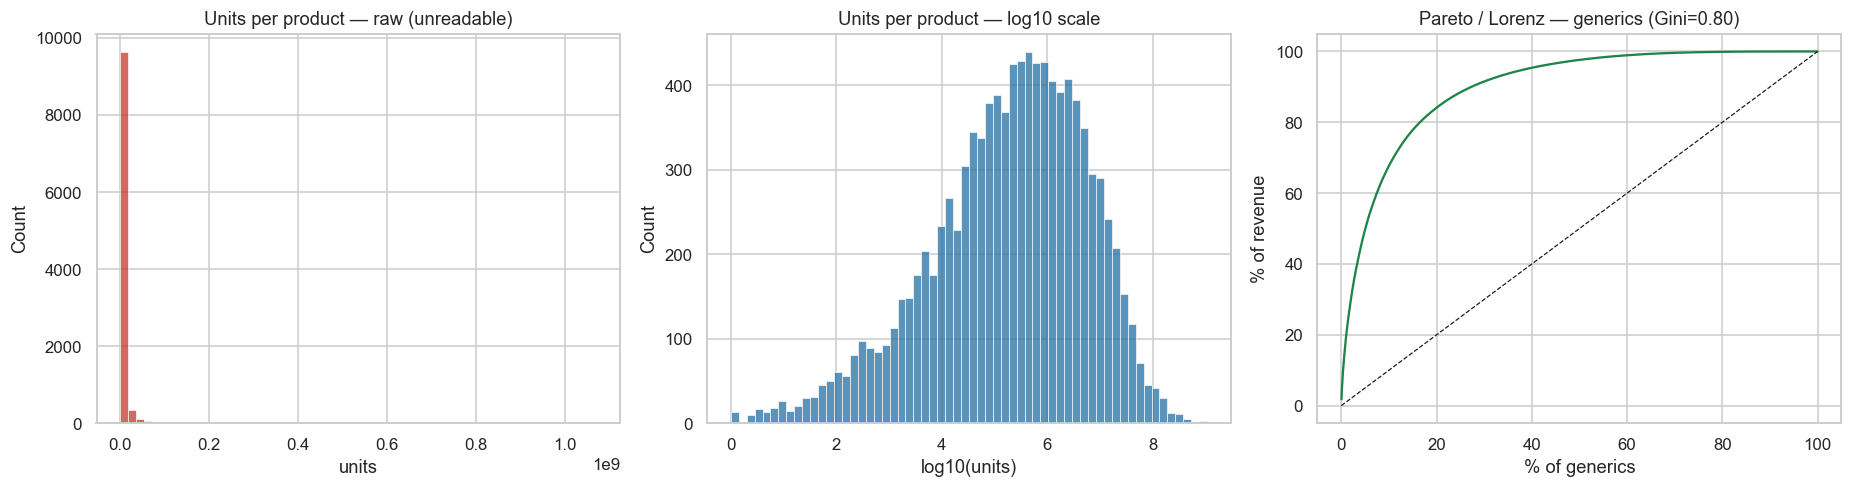

C:\Users\Notebook\AppData\Local\Temp\ipykernel_18048\4146946800.py:58: UserWarning: Glyph 8209 (\N{NON-BREAKING HYPHEN}) missing from font(s) Arial.
  plt.tight_layout(); plt.savefig(OUTPUT_DIR / name, dpi=200, bbox_inches="tight"); plt.show()
C:\Users\Notebook\AppData\Roaming\Python\Python310\site-packages\IPython\core\pylabtools.py:151: UserWarning: Glyph 8209 (\N{NON-BREAKING HYPHEN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


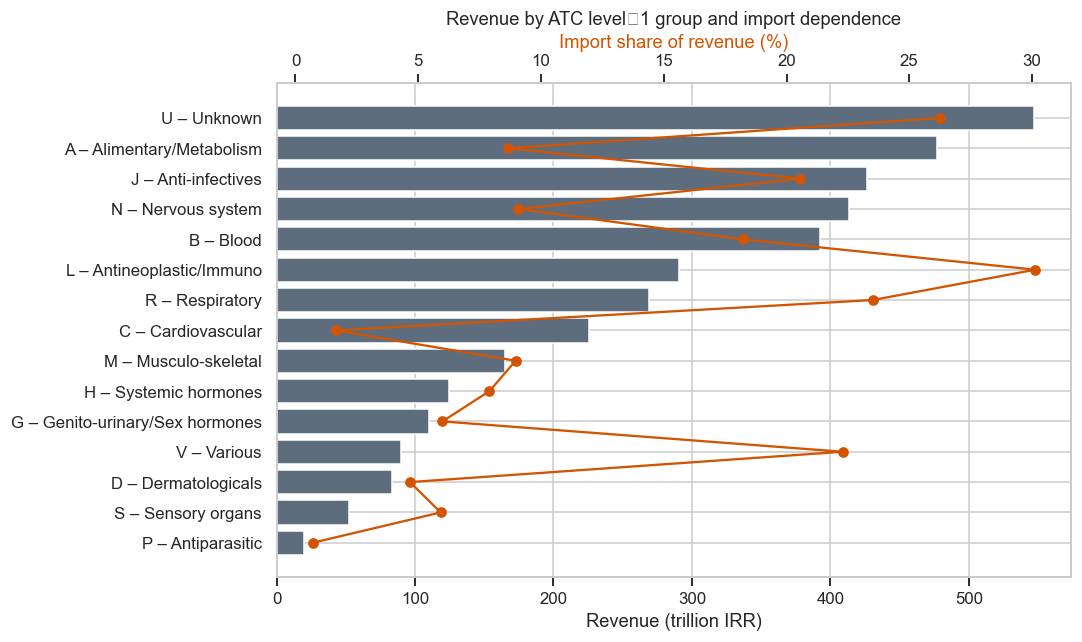

In [7]:
def gini(x):
    x = np.sort(np.asarray(x, float)); x = x[x > 0]; n = len(x)
    return (2*np.sum(np.arange(1, n+1)*x) / (n*x.sum())) - (n+1)/n

desc = pd.DataFrame({"raw": active.units.describe(percentiles=[.25,.5,.75,.95]),
                     "log10": active.log_units.describe(percentiles=[.25,.5,.75,.95])})
display(desc)
print(f"Skew خام: {stats.skew(active.units):.1f} | Skew لگاریتمی: {stats.skew(active.log_units):.2f}")
print(f"Gini فروش ریالی محصولات: {gini(active.revenue):.3f} | ژنریک‌ها: {gini(gen.revenue):.3f}")
gs = gen.sort_values("revenue", ascending=False).revenue.values; cum = gs.cumsum()/gs.sum()
for p in (0.01, 0.05, 0.10, 0.20):
    print(f"Top {p:>4.0%} ژنریک‌ها → {cum[int(len(gs)*p)-1]:.1%} فروش ریالی")


dist_sh = df.groupby("distributor").revenue.sum().sort_values(ascending=False); dist_sh /= dist_sh.sum()
sup_sh_all = df.groupby("supplier").revenue.sum().sort_values(ascending=False); sup_sh_all /= sup_sh_all.sum()
print(f"\nHHI پخش: {(dist_sh**2).sum():.3f} | سهم ۵ پخش برتر: {dist_sh.head(5).sum():.1%}"
      f" | HHI تأمین‌کنندگان: {(sup_sh_all**2).sum():.3f} | سهم ۱۰ تأمین‌کننده‌ی برتر: {sup_sh_all.head(10).sum():.1%}")
imp_share = df.loc[df.is_import==1, "revenue"].sum()/df.revenue.sum()
print(f"سهم کالای وارداتی از فروش ریالی: {imp_share:.1%} | از نظر تعداد واحد: {df.loc[df.is_import==1,'units'].sum()/df.units.sum():.1%}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
sns.histplot(active.units, bins=60, ax=ax[0], color="#c0392b"); ax[0].set_title("Units per product — raw (unreadable)"); ax[0].set_xlabel("units")
sns.histplot(active.log_units, bins=60, ax=ax[1], color="#2471a3"); ax[1].set_title("Units per product — log10 scale"); ax[1].set_xlabel("log10(units)")
ax[2].plot(np.arange(1, len(gs)+1)/len(gs)*100, cum*100, color="#1e8449"); ax[2].plot([0,100],[0,100], "k--", lw=.8)
ax[2].set_title(f"Pareto / Lorenz — generics (Gini={gini(gen.revenue):.2f})"); ax[2].set_xlabel("% of generics"); ax[2].set_ylabel("% of revenue")
savefig("01_distribution_pareto.png")


t = df.groupby("atc1").agg(revenue=("revenue","sum"))
t["import_share"] = df[df.is_import==1].groupby("atc1").revenue.sum()/t.revenue
t["label"] = [f"{k} – {ATC1_NAMES.get(k,k)}" for k in t.index]; t = t.sort_values("revenue")
fig, ax = plt.subplots(figsize=(10, 6)); ax.barh(t.label, t.revenue/1e12, color="#5d6d7e"); ax.set_xlabel("Revenue (trillion IRR)")
ax2 = ax.twiny(); ax2.plot(t.import_share*100, t.label, "o-", color="#d35400"); ax2.set_xlabel("Import share of revenue (%)", color="#d35400"); ax2.grid(False)
ax.set_title("Revenue by ATC level‑1 group and import dependence"); savefig("02_atc_revenue_import.png")

### Simple Statistical Tests (Focusing on Effect Size, Not Just p-values)

With approximately 10,000 products, p-values are likely to be statistically significant in most cases. Therefore, **effect size** (Cliff's δ) is more important than statistical significance alone.

In [8]:
def cliffs_delta(x, y):
    u = stats.mannwhitneyu(x, y, alternative="two-sided"); return u.pvalue, 2*u.statistic/(len(x)*len(y)) - 1

rows = []
for name, mask in {"وارداتی در برابر تولیدی": active.is_import == 1, "OTC در برابر نسخه‌ای": active.otc == 1}.items():
    for var in ["log_price", "log_units"]:
        p, d = cliffs_delta(active.loc[mask, var], active.loc[~mask, var])
        rows.append({"مقایسه": name, "متغیر": var, "میانه گروه ۱": active.loc[mask, var].median(),
                     "میانه گروه ۲": active.loc[~mask, var].median(), "p-value": p, "Cliff's δ": d})
display(pd.DataFrame(rows))
rho, pv = stats.spearmanr(active.log_price, active.log_units)
print(f"Spearman(قیمت واحد، حجم فروش) = {rho:.2f} (p={pv:.1e}) → داروهای گران‌تر به‌طور میانگین حجم کمتری دارند (همبستگی، نه علیت).")

,مقایسه,متغیر,میانه گروه ۱,میانه گروه ۲,p-value,Cliff's δ
0,وارداتی در برابر تولیدی,log_price,6.204,4.778,0.000,0.581
1,وارداتی در برابر تولیدی,log_units,4.112,5.596,0.000,-0.521
2,OTC در برابر نسخه‌ای,log_price,4.653,4.987,0.000,-0.141
3,OTC در برابر نسخه‌ای,log_units,5.535,5.408,0.001,0.054


Spearman(قیمت واحد، حجم فروش) = -0.51 (p=0.0e+00) → داروهای گران‌تر به‌طور میانگین حجم کمتری دارند (همبستگی، نه علیت).


### 6) Outlier Detection

**Issues with the previous version:**

1. Isolation Forest was applied to IRC and Generic Product Code, which are identifiers rather than meaningful features, as well as raw monetary columns with scales reaching 10¹⁵.
2. The analysis was performed on duplicated Product × Distributor rows.
3. A contamination parameter of 5% was used without justification.
4. No explanation was provided for why an observation was classified as an outlier.

**New Approach — Three Layers:**

1. **Business Rules:** Detect large returns, zero prices, and violations of the price chain.
2. **Isolation Forest:** Apply the model to standardized, log-transformed product-level features, with explanations based on the features showing the largest deviations.
3. **Within-Generic Price Outliers:** Use Robust Z-scores (MAD) to identify pricing anomalies by comparing one brand's price against other brands containing the same active ingredient.

,تعداد
سطرهای برگشتی (units<0),450
محصولات با نرخ برگشت >۲۰٪ و حجم ناخالص ≥۱۰۰۰ واحد,18
قیمت تامین‌کننده = 0,10


Isolation Forest: 206 محصول (2.0%) | پرت قیمتی هم‌ژنریک: 102 | هر دو: 14


,irc,brand,generic,units,p_consumer,n_dist,dist_hhi,if_score,outlier_reason
8943,8702163083792939,آدستریس پودر برای تهیه محلول تزری,"BRENTUXIMAB VEDOTIN INJECTION, POWDER, F",5,"680,890,000.000",1,1.000,0.664,log_price (z=3.7)
3470,3918707376838315,سرزایم پودر برای تهیه محلول تزریق,"IMIGLUCERASE INJECTION, POWDER, FOR SOLU",2,"191,213,800.000",1,1.000,0.654,log_units (z=-3.3)
5056,5346436394468584,اسپینرازا محلول تزریقی پرنترال 2.,"NUSINERSEN (AS SODIUM) INJECTION, SOLUTI",19,"407,071,000.000",1,1.000,0.651,margin (z=-4.4)
7122,7140727614590747,فوسکاویر محلول تزریقی پرنترال 24,"FOSCARNET SODIUM INJECTION, SOLUTION PAR",3,"170,870,000.000",1,1.000,0.651,margin (z=-3.3)
4721,5080772247774655,آگیلوس پودر برای تهیه فرآورده تزر,"DANTROLENE SODIUM INJECTION, POWDER PARE",186,"313,580,000.000",1,1.000,0.647,margin (z=-3.4)
5307,5554473831934958,برینرت پودر برای تهیه محلول تزریق,C1-ESTRASE INHIBITOR PLASMA DERIVED INJE,9,"272,664,000.000",1,1.000,0.646,log_price (z=3.3)
4591,4947860242653179,ویزوداین پودر برای تهیه محلول تزر,"VERTEPORFIN INJECTION, POWDER, FOR SOLUT",25,"803,736,000.000",1,1.000,0.646,log_price (z=3.8)
5074,5355112159083477,ادسرتیس پودر برای تهیه محلول تزری,"BRENTUXIMAB VEDOTIN INJECTION, POWDER, F",19,"792,210,000.000",1,1.000,0.645,log_price (z=3.7)
4290,4679800071532995,دیجیفب تزریقی پرنترال 40 mg mg,DIGOXIN SPECIFIC ANTIBODY INJECTION PARE,7,"1,641,000,000.000",1,1.000,0.645,log_price (z=4.1)
2721,3282135363542342,کارموستین پودر برای تهیه محلول تز,"CARMUSTINE INJECTION, POWDER, FOR SOLUTI",6,"1,293,250,000.000",1,1.000,0.639,log_price (z=4.0)


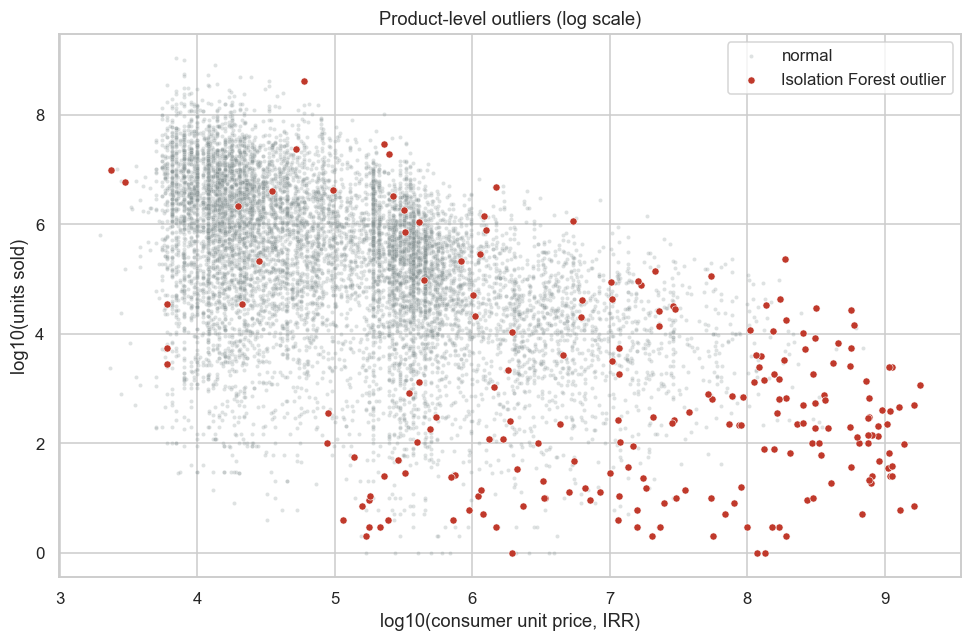

In [9]:
OUT_FEATS = ["log_units", "log_price", "margin", "log_pack", "log_ndist", "dist_hhi"]   # برگشتی در لایه‌ی قواعد بررسی می‌شود
Xo = StandardScaler().fit_transform(active[OUT_FEATS])
iso = IsolationForest(n_estimators=400, contamination=CONTAMINATION, random_state=RANDOM_STATE, n_jobs=-1).fit(Xo)
active["if_score"] = -iso.score_samples(Xo)                 # بزرگ‌تر = غیرعادی‌تر
active["is_outlier_if"] = iso.predict(Xo) == -1

zdf = pd.DataFrame(Xo, columns=OUT_FEATS, index=active.index)
top = zdf.abs().idxmax(axis=1)
active["outlier_reason"] = top + " (z=" + pd.Series([zdf.at[i, c] for i, c in top.items()], index=top.index).round(1).astype(str) + ")"

# پرت قیمتی در بین برندهای هم‌ژنریک
grp = active.groupby("generic_code").log_price
med, mad, cnt = grp.transform("median"), grp.transform(lambda x: (x - x.median()).abs().median()), grp.transform("count")
active["price_robust_z"] = 0.6745 * (active.log_price - med) / mad.replace(0, np.nan)
active["is_price_outlier"] = (cnt >= 5) & (active.price_robust_z.abs() > 3.5)

# قواعد کسب‌وکاری در سطح سطر
biz = pd.Series({
  "سطرهای برگشتی (units<0)": int((df.units < 0).sum()),
  "محصولات با نرخ برگشت >۲۰٪ و حجم ناخالص ≥۱۰۰۰ واحد": int(((prod.return_rate > .2) & (prod.gross_units >= 1000)).sum()),
  "قیمت تامین‌کننده = 0": int((prod.p_supplier == 0).sum()),
}).to_frame("تعداد"); display(biz)
print(f"Isolation Forest: {active.is_outlier_if.sum():,} محصول ({active.is_outlier_if.mean():.1%}) | "
      f"پرت قیمتی هم‌ژنریک: {active.is_price_outlier.sum():,} | هر دو: {(active.is_outlier_if & active.is_price_outlier).sum():,}")
cols = ["irc","brand","generic","units","p_consumer","n_dist","dist_hhi","if_score","outlier_reason"]
display(active.loc[active.is_outlier_if].sort_values("if_score", ascending=False)[cols].head(12).assign(brand=lambda d: d.brand.str[:35], generic=lambda d: d.generic.str[:40]))

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=active[~active.is_outlier_if], x="log_price", y="log_units", s=7, alpha=.25, color="#7f8c8d", ax=ax, label="normal")
sns.scatterplot(data=active[active.is_outlier_if], x="log_price", y="log_units", s=22, color="#c0392b", ax=ax, label="Isolation Forest outlier")
ax.set_title("Product-level outliers (log scale)"); ax.set_xlabel("log10(consumer unit price, IRR)"); ax.set_ylabel("log10(units sold)"); savefig("03_outliers.png")

## 7) Product Clustering

C:\Users\Notebook\AppData\Roaming\Python\Python310\site-packages\joblib\externals\loky\backend\context.py:110: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Notebook\AppData\Roaming\Python\Python310\site-packages\joblib\externals\loky\backend\context.py", line 199, in _count_physical_cores
    cpu_info = subprocess.run(
  File "c:\Program Files\Python310\lib\subprocess.py", line 501, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\Program Files\Python310\lib\subprocess.py", line 969, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Program Files\Python310\lib\subprocess.py", line 1438, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, ar

,k,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share,inertia
0,2,0.380,1.362,"4,218.412",0.226,"58,308.543"
1,3,0.307,1.381,"3,959.522",0.132,"46,448.624"
2,4,0.339,1.149,"4,076.439",0.038,"37,551.050"
3,5,0.367,1.033,"4,440.924",0.038,"30,137.511"
4,6,0.325,1.001,"4,589.332",0.038,"25,434.044"
5,7,0.351,0.979,"4,497.837",0.038,"22,674.476"
6,8,0.340,1.028,"4,459.983",0.038,"20,359.886"
7,9,0.348,1.028,"4,479.668",0.038,"18,319.647"
8,10,0.308,1.083,"4,358.379",0.038,"17,064.314"


k با بیشینه‌ی سیلوئت (آماری): 2 — معمولاً فقط تفکیک «ارزان‌پرحجم» از «گران‌کم‌حجم» است
k منتخب برای بخش‌بندی کاربردی (4–8، حداقل اندازه 3%): 5
پایداری خوشه‌ها (ARI میانگین ± sd): 0.99 ± 0.00   (>0.8 پایدار)


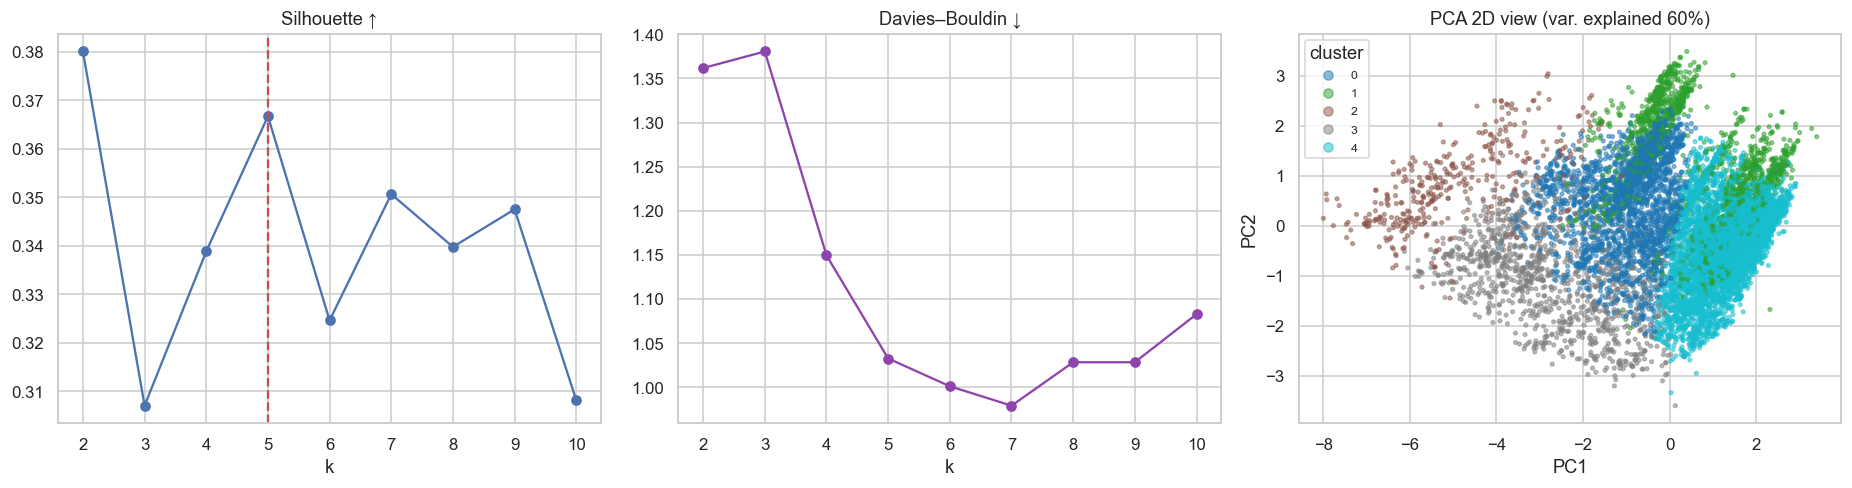

,n,revenue_share,med_units,med_price,med_margin,med_pack,med_ndist,import_share,otc_share,licensed_share,biologic_share,return_rate,top_atc1,n_share
cluster,,,,,,,,,,,,,,
0,2473,0.166,"44,900.000","500,000.000",0.237,1.000,5.000,0.000,0.002,0.009,0.000,0.002,"L, D",0.241
1,1456,0.090,"349,740.000","45,000.000",0.298,10.000,8.000,0.004,1.000,0.001,0.000,0.000,"R, A",0.142
2,394,0.223,"10,383.500","29,000,000.000",0.150,1.000,2.000,0.596,0.000,0.003,1.000,0.002,"U, B",0.038
3,1042,0.069,"16,932.500","849,000.000",0.150,4.500,1.000,1.000,0.014,0.000,0.000,0.003,"U, L",0.101
4,4915,0.451,"1,390,750.000","23,900.000",0.309,30.000,6.000,0.006,0.000,0.013,0.000,0.001,"N, A",0.478



بارهای PCA (برای تفسیر نمودار):


,PC1,PC2
log_units,0.380,0.250
log_price,-0.470,0.260
margin,0.480,-0.100
log_pack,0.370,-0.480
log_ndist,0.260,0.640
is_import,-0.350,-0.250
otc,0.080,0.370
is_biologic,-0.270,0.120


In [10]:
# حذف عمدی: return_rate (دم سنگین، در لایه‌ی ناهنجاری)، licensed (فقط ۰٫۹٪ سطرها؛ خودش یک خوشه‌ی مصنوعی می‌ساخت)، dist_hhi (هم‌خط با n_dist)
CL_FEATS = ["log_units", "log_price", "margin", "log_pack", "log_ndist", "is_import", "otc", "is_biologic"]
Xc = StandardScaler().fit_transform(active[CL_FEATS])
MIN_SHARE = 0.03
res = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xc)
    res.append({"k": k, "silhouette": silhouette_score(Xc, km.labels_, sample_size=6000, random_state=RANDOM_STATE),
                "davies_bouldin": davies_bouldin_score(Xc, km.labels_), "calinski_harabasz": calinski_harabasz_score(Xc, km.labels_),
                "min_cluster_share": np.bincount(km.labels_).min()/len(Xc), "inertia": km.inertia_})
cl_eval = pd.DataFrame(res); display(cl_eval)
ok = cl_eval[cl_eval.min_cluster_share >= MIN_SHARE]
k_stat = int(ok.loc[ok.silhouette.idxmax(), "k"])
K_SEG_RANGE = (4, 8)                       # برای بخش‌بندی قابل‌اقدام، حداقل ۴ و حداکثر ۸ بخش
seg_ok = ok[ok.k.between(*K_SEG_RANGE)]
best_k = int(seg_ok.loc[seg_ok.silhouette.idxmax(), "k"]) if len(seg_ok) else k_stat
print(f"k با بیشینه‌ی سیلوئت (آماری): {k_stat} — معمولاً فقط تفکیک «ارزان‌پرحجم» از «گران‌کم‌حجم» است")
print(f"k منتخب برای بخش‌بندی کاربردی ({K_SEG_RANGE[0]}–{K_SEG_RANGE[1]}، حداقل اندازه {MIN_SHARE:.0%}): {best_k}")

km = KMeans(n_clusters=best_k, n_init=20, random_state=RANDOM_STATE).fit(Xc); active["cluster"] = km.labels_

# پایداری: برازش روی ۸۰٪ نمونه، برچسب‌گذاری کل، مقایسه با مدل مرجع
rng = np.random.default_rng(RANDOM_STATE); aris = []
for _ in range(15):
    idx = rng.choice(len(Xc), int(.8*len(Xc)), replace=False)
    k2 = KMeans(n_clusters=best_k, n_init=5, random_state=int(rng.integers(1e6))).fit(Xc[idx])
    aris.append(adjusted_rand_score(km.labels_, k2.predict(Xc)))
print(f"پایداری خوشه‌ها (ARI میانگین ± sd): {np.mean(aris):.2f} ± {np.std(aris):.2f}   (>0.8 پایدار)")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
ax[0].plot(cl_eval.k, cl_eval.silhouette, "o-"); ax[0].axvline(best_k, color="r", ls="--"); ax[0].set_title("Silhouette ↑"); ax[0].set_xlabel("k")
ax[1].plot(cl_eval.k, cl_eval.davies_bouldin, "o-", color="#8e44ad"); ax[1].set_title("Davies–Bouldin ↓"); ax[1].set_xlabel("k")
pca = PCA(n_components=2, random_state=RANDOM_STATE); Z = pca.fit_transform(Xc)
sc = ax[2].scatter(Z[:,0], Z[:,1], c=active.cluster, cmap="tab10", s=6, alpha=.5)
ax[2].set_title(f"PCA 2D view (var. explained {pca.explained_variance_ratio_.sum():.0%})"); ax[2].set_xlabel("PC1"); ax[2].set_ylabel("PC2")
ax[2].legend(*sc.legend_elements(), title="cluster", loc="best", fontsize=8); savefig("04_clustering_eval.png")

prof = active.groupby("cluster").agg(n=("irc","count"), revenue_share=("revenue", lambda s: s.sum()/active.revenue.sum()),
        med_units=("units","median"), med_price=("p_consumer","median"), med_margin=("margin","median"), med_pack=("pack_size","median"),
        med_ndist=("n_dist","median"), import_share=("is_import","mean"), otc_share=("otc","mean"), licensed_share=("licensed","mean"),
        biologic_share=("is_biologic","mean"), return_rate=("return_rate","mean"))
prof["top_atc1"] = active.groupby("cluster").atc1.agg(lambda s: ", ".join(s.value_counts(normalize=True).head(2).index))
prof["n_share"] = prof.n/prof.n.sum(); display(prof)

lo = pd.DataFrame(pca.components_.T, index=CL_FEATS, columns=["PC1","PC2"]); print("\nبارهای PCA (برای تفسیر نمودار):"); display(lo.round(2))

## 8) Predictive Modeling: What Factors Explain a Product’s Sales Volume?

- **Target:** `log10(units)` — net unit sales per product.
- **Features:** Only intrinsic product and market characteristics, including price, pack size, OTC status, import status, licensing status, biologic status, ATC group, country, supplier portfolio size, and the number of competitors within the same generic category.
- **Intentionally excluded:** Any variables derived from sales data itself, such as monetary sales, package quantity, and number of distributors, to prevent target leakage.
- **Validation:** `GroupKFold`, with the generic product as the grouping variable. This means the model is evaluated on **unseen generic products**, providing a stricter and more realistic assessment than a random train-test split.
- **Model comparison:** Compare a simple mean baseline against Ridge Regression, Random Forest, and Gradient Boosting.

,model,R2_cv,MAE_log10,typical_error_factor
3,Gradient Boosting,0.369,0.906,8.047
2,Random Forest,0.369,0.906,8.062
1,Ridge,0.323,0.950,8.913
0,Baseline (mean),-0.001,1.186,15.355


بهترین مدل: Gradient Boosting | یعنی خطای معمول پیش‌بینی ≈ ×8.0 برابر/کمتر از فروش واقعی
R² روی hold‑out گروهی: 0.373


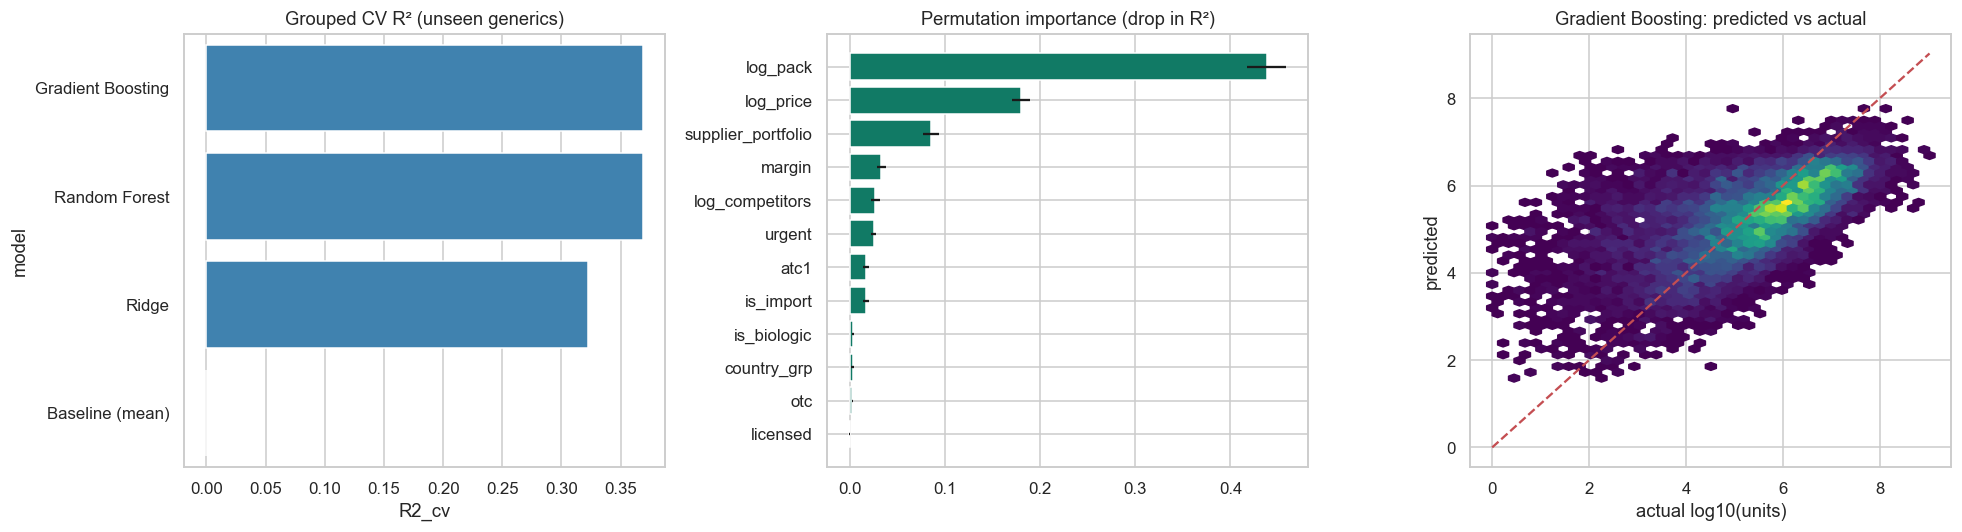

In [11]:
m = active.copy()
top_c = m.country.value_counts().head(6).index
m["country_grp"] = np.where(m.country.isin(top_c), m.country, "Other")
m["supplier_portfolio"] = np.log10(m.groupby("supplier").irc.transform("count"))
m["log_competitors"]    = np.log10(m.groupby("generic_code").irc.transform("count"))
NUM = ["log_price", "log_pack", "margin", "supplier_portfolio", "log_competitors", "otc", "licensed", "is_import", "is_biologic", "urgent"]
CAT = ["atc1", "country_grp"]
X, y, groups = m[NUM + CAT], m.log_units, m.generic_code

pre = ColumnTransformer([("num", StandardScaler(), NUM),
                         ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False, min_frequency=20), CAT)])
models = {
  "Baseline (mean)":      DummyRegressor(strategy="mean"),
  "Ridge":                Ridge(alpha=3.0),
  "Random Forest":        RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=RANDOM_STATE),
  "Gradient Boosting":    HistGradientBoostingRegressor(max_depth=5, learning_rate=0.06, max_iter=300, l2_regularization=1.0, random_state=RANDOM_STATE),
}
cv = GroupKFold(n_splits=5); scores, preds = [], {}
for name, est in models.items():
    pipe = Pipeline([("pre", pre), ("model", est)])
    p = cross_val_predict(pipe, X, y, cv=cv, groups=groups, n_jobs=1); preds[name] = p
    scores.append({"model": name, "R2_cv": r2_score(y, p), "MAE_log10": mean_absolute_error(y, p),
                   "typical_error_factor": 10**mean_absolute_error(y, p)})
model_scores = pd.DataFrame(scores).sort_values("R2_cv", ascending=False); display(model_scores)
best_name = model_scores.iloc[0].model
print(f"بهترین مدل: {best_name} | یعنی خطای معمول پیش‌بینی ≈ ×{model_scores.iloc[0].typical_error_factor:.1f} برابر/کمتر از فروش واقعی")

# اهمیت ویژگی (Permutation) روی یک hold‑out گروهی
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=.2, random_state=RANDOM_STATE).split(X, y, groups))
best_pipe = Pipeline([("pre", pre), ("model", models[best_name])]).fit(X.iloc[tr], y.iloc[tr])
pi = permutation_importance(best_pipe, X.iloc[te], y.iloc[te], n_repeats=10, random_state=RANDOM_STATE, scoring="r2")
imp = pd.DataFrame({"feature": X.columns, "importance": pi.importances_mean, "sd": pi.importances_std}).sort_values("importance")
print(f"R² روی hold‑out گروهی: {best_pipe.score(X.iloc[te], y.iloc[te]):.3f}")

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(data=model_scores, y="model", x="R2_cv", ax=ax[0], color="#2e86c1"); ax[0].set_title("Grouped CV R² (unseen generics)")
ax[1].barh(imp.feature, imp.importance, xerr=imp.sd, color="#117a65"); ax[1].set_title("Permutation importance (drop in R²)")
ax[2].hexbin(y, preds[best_name], gridsize=40, cmap="viridis", mincnt=1); ax[2].plot([y.min(), y.max()], [y.min(), y.max()], "r--")
ax[2].set_xlabel("actual log10(units)"); ax[2].set_ylabel("predicted"); ax[2].set_title(f"{best_name}: predicted vs actual"); savefig("05_model_eval.png")

## 9) Supply Vulnerability Index (Replacing the Previous “Shortage Risk” Metric)

Risk = **Supply Vulnerability × Impact** (market importance).

- **Supply Vulnerability (0–1):** Measured using supplier concentration (HHI), import dependency, single-source supply (number of manufacturers), and distribution concentration.
- **Impact:** The percentile rank of monetary sales.

**Important:** This is a **transparent, heuristic index**, not a trained predictive model. The dataset contains no ground-truth shortage labels. The weights are adjustable, and **sensitivity analysis** is used to assess the stability of the resulting monitoring list.

quadrant
Lower priority                      1384
Resilient, high impact               419
Fragile, lower impact                419
WATCHLIST: fragile & high impact      32
ژنریک‌های فهرست پایش: 32 | از این‌ها پایدار (≥۸۰٪ وزن‌های تصادفی): 20


,generic,revenue,n_manufacturer,supplier_hhi,import_share,fragility,impact,watchlist_stability
1305,"NATALIZUMAB INJECTION, SOLUTION, CONCENTRATE P...",10642131670000,1,1.000,1.000,0.993,0.966,1.000
1299,"ALGLUCOSIDASE ALFA INJECTION, POWDER, FOR SOLU...",8166667566650,1,1.000,1.000,0.993,0.951,1.000
1311,INSULIN GLARGINE INJECTION PARENTERAL 300 [iU]...,8063492724000,1,1.000,1.000,0.972,0.949,1.000
1816,BECLOMETHASONE DIPROPIONATE / FORMOTEROL FUMAR...,6337095230000,1,1.000,1.000,0.982,0.933,1.000
2083,HUMAN PAPILLOMAVIRUS VACCINE (9-VALENT) INJECT...,14084235950000,1,1.000,1.000,0.930,0.978,0.829
1209,"FACTOR VIII / VON WILLEBRAND FACTOR INJECTION,...",4848425499000,1,1.000,1.000,0.993,0.912,1.000
1525,"BUDESONIDE / FORMOTEROL FUMARATE POWDER, METER...",3849661010000,1,1.000,1.000,0.993,0.892,1.000
1309,GALSULFASE INJECTION PARENTERAL 1 mg/1mL 5 mL,3507544064000,1,1.000,1.000,0.993,0.879,1.000
1413,"ROMIPLOSTIM INJECTION, POWDER, FOR SOLUTION PA...",6336070950000,1,1.000,1.000,0.934,0.932,0.844
1573,"ELOSULFASE ALFA INJECTION, SOLUTION, CONCENTRA...",3319641250000,1,1.000,1.000,0.993,0.875,1.000


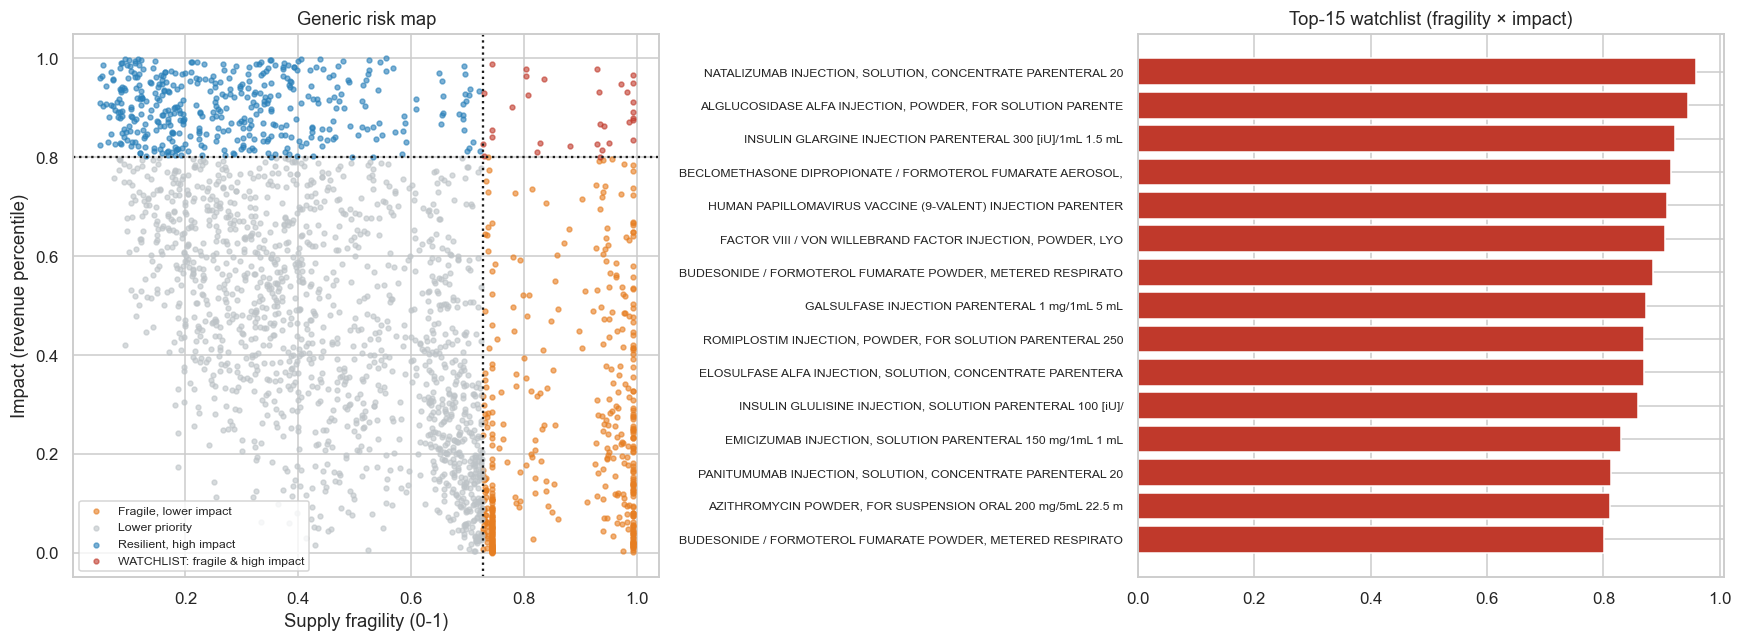

In [12]:
W = {"supplier_hhi": 0.35, "import_share": 0.25, "single_source": 0.25, "dist_rank": 0.15}   # قابل ویرایش
gen["single_source"] = 1 / gen.n_manufacturer
gen["dist_rank"] = gen.dist_hhi.rank(pct=True)
comp = gen[list(W)]
gen["fragility"] = comp.mul(pd.Series(W)).sum(axis=1)
gen["impact"] = gen.revenue.rank(pct=True)
gen["priority_score"] = gen.fragility * gen.impact

q_f, q_i = gen.fragility.quantile(.80), gen.impact.quantile(.80)
gen["quadrant"] = np.select([(gen.fragility>=q_f)&(gen.impact>=q_i), (gen.fragility>=q_f), (gen.impact>=q_i)],
                            ["WATCHLIST: fragile & high impact", "Fragile, lower impact", "Resilient, high impact"], "Lower priority")
print(gen.quadrant.value_counts().to_string())

# حساسیت‌سنجی: ۱۰۰۰ وزن تصادفی (Dirichlet)؛ هر ژنریک در چند درصد حالات در پنج‌ک بالای شکنندگی و اثر می‌ماند؟
rng = np.random.default_rng(RANDOM_STATE); Wd = rng.dirichlet(np.ones(4), size=1000)
F = comp.values @ Wd.T                                                   # n_generic × 1000
hit = ((F >= np.quantile(F, .80, axis=0)) & (gen.impact.values[:, None] >= q_i)).mean(axis=1)
gen["watchlist_stability"] = hit
robust = gen[(gen.quadrant.str.startswith("WATCHLIST")) & (gen.watchlist_stability >= .8)]
print(f"ژنریک‌های فهرست پایش: {(gen.quadrant.str.startswith('WATCHLIST')).sum()} | از این‌ها پایدار (≥۸۰٪ وزن‌های تصادفی): {len(robust)}")

watch = gen[gen.quadrant.str.startswith("WATCHLIST")].sort_values("priority_score", ascending=False)
display(watch.head(15)[["generic","revenue","n_manufacturer","supplier_hhi","import_share","fragility","impact","watchlist_stability"]]
        .assign(generic=lambda d: d.generic.str[:55]))

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
cm = {"WATCHLIST: fragile & high impact":"#c0392b","Fragile, lower impact":"#e67e22","Resilient, high impact":"#2980b9","Lower priority":"#bdc3c7"}
for qn, d in gen.groupby("quadrant"): ax[0].scatter(d.fragility, d.impact, s=10, alpha=.6, label=qn, color=cm[qn])
ax[0].axvline(q_f, color="k", ls=":"); ax[0].axhline(q_i, color="k", ls=":"); ax[0].legend(fontsize=8); ax[0].set_xlabel("Supply fragility (0-1)"); ax[0].set_ylabel("Impact (revenue percentile)")
ax[0].set_title("Generic risk map")
t15 = watch.head(15).iloc[::-1]; yy = np.arange(len(t15))          # موقعیت عددی؛ برچسب‌های کوتاه‌شده‌ی مشابه روی هم نیفتند
ax[1].barh(yy, t15.priority_score, color="#c0392b"); ax[1].set_yticks(yy); ax[1].set_yticklabels([s[:58] for s in t15.generic], fontsize=8)
ax[1].set_title("Top-15 watchlist (fragility × impact)")
savefig("06_supply_risk.png")

## 10) “Forecasting Next Year’s Sales” and Inflation Scenarios

**New Model**

- **New Price:** `Price × (1 + Inflation × Pass-Through Rate)`
- **New Volume:** `Volume × (New Price / Old Price)^Elasticity`

The **pass-through rate** and **price elasticity** vary by market segment.

**Important:** The parameters used below are **illustrative assumptions**, not empirically estimated values. They should be calibrated using domain knowledge and market-specific factors, such as regulated pricing policies, exchange-rate movements, and other relevant market conditions.

,revenue_change_%,units_change_%
A – demand-sensitive (elasticity ×2),13.857,-7.040
B – base,18.215,-3.659
C – demand-resilient (elasticity ×0.5),20.496,-1.866


,price_change,rev_chg_pct,units_chg_pct
Rx – domestic (regulated),0.180,16.063,-1.642
OTC – domestic,0.270,12.694,-11.264
Imported / licensed / biologic,0.300,23.354,-5.112


Monte Carlo — تغییر درآمد اسمی: میانه 17.7% | بازه‌ی ۹۰٪: [11.4, 26.1]%
Monte Carlo — تغییر حجم: میانه -4.5% | بازه‌ی ۹۰٪: [-7.8, -2.1]%


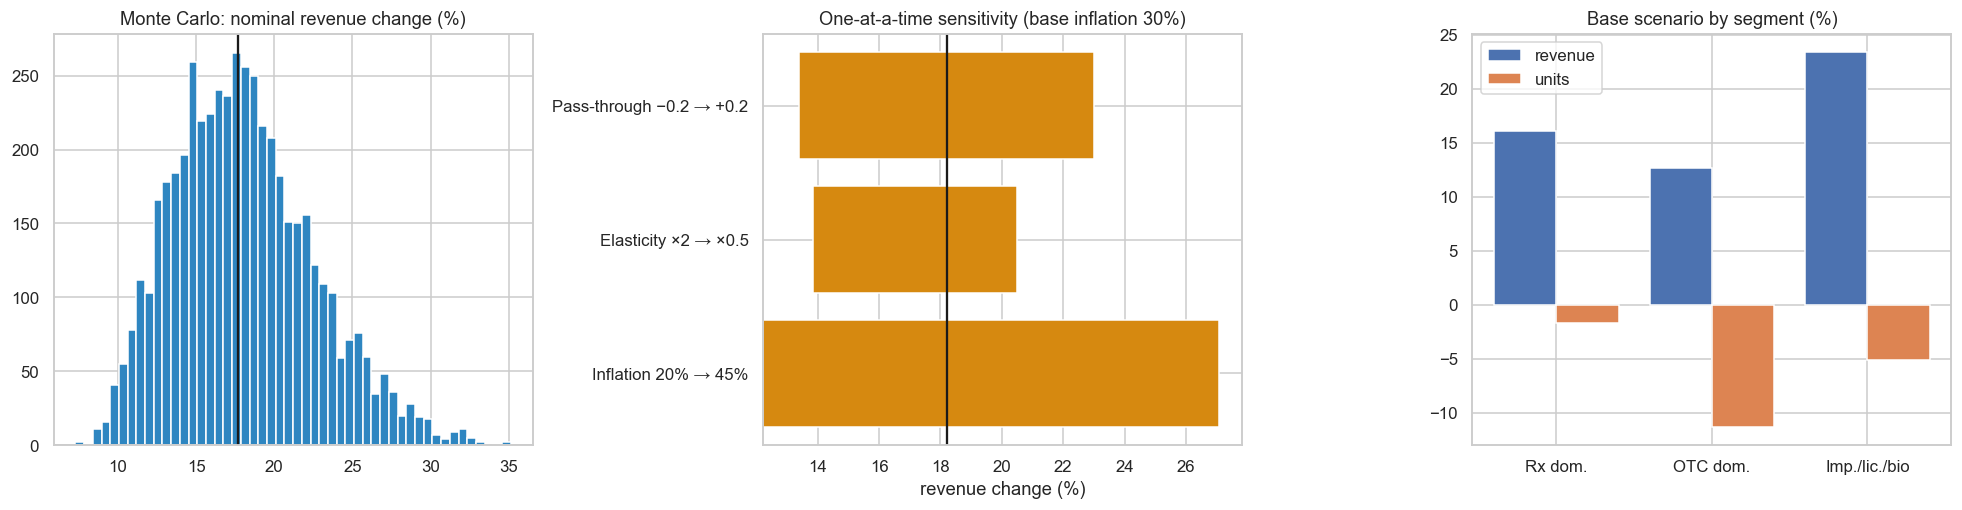


تفاوت تغییر درآمد بین ژنریک‌ها در سناریوی پایه (برخلاف نسخه‌ی قبل ثابت نیست):
count   2,254.000
mean       17.500
std         3.300
min        12.700
5%         12.700
50%        16.100
95%        23.400
max        23.400


In [13]:
INFLATION_BASE = 0.30
SEG = pd.DataFrame({"pass_through": [0.60, 0.90, 1.00], "elasticity": [-0.10, -0.50, -0.20]},
                   index=["Rx – domestic (regulated)", "OTC – domestic", "Imported / licensed / biologic"])
def segment(p): return np.where((p.is_import==1)|(p.licensed==1)|(p.is_biologic==1), SEG.index[2], np.where(p.otc==1, SEG.index[1], SEG.index[0]))
prod["segment"] = segment(prod)
df["segment"] = df.irc.map(prod.set_index("irc").segment)
base = df.groupby("segment").agg(revenue=("revenue","sum"), units=("units","sum")).reindex(SEG.index)

def run(infl, elast_mult=1.0, pt_shift=0.0, tab=base):
    dp = infl * (SEG.pass_through + pt_shift).clip(0, 1.2)
    vol = (1 + dp) ** (SEG.elasticity * elast_mult)
    return pd.DataFrame({"revenue0": tab.revenue, "revenue1": tab.revenue*(1+dp)*vol, "units0": tab.units, "units1": tab.units*vol, "price_change": dp})

scen = {"A – demand-sensitive (elasticity ×2)": run(INFLATION_BASE, 2.0), "B – base": run(INFLATION_BASE, 1.0), "C – demand-resilient (elasticity ×0.5)": run(INFLATION_BASE, 0.5)}
summ = pd.DataFrame({k: {"revenue_change_%": (v.revenue1.sum()/v.revenue0.sum()-1)*100, "units_change_%": (v.units1.sum()/v.units0.sum()-1)*100} for k, v in scen.items()}).T
display(summ); display((scen["B – base"].assign(rev_chg_pct=lambda d: (d.revenue1/d.revenue0-1)*100, units_chg_pct=lambda d: (d.units1/d.units0-1)*100)[["price_change","rev_chg_pct","units_chg_pct"]]))

# عدم‌قطعیت: Monte Carlo روی تورم، ضریب انتقال و کشش
rng = np.random.default_rng(RANDOM_STATE); N = 5000; out = np.empty(N); outu = np.empty(N)
for i in range(N):
    infl = rng.triangular(0.20, 0.30, 0.45); r = run(infl, elast_mult=rng.uniform(.5, 2.0), pt_shift=rng.uniform(-.2, .2))
    out[i] = r.revenue1.sum()/r.revenue0.sum()-1; outu[i] = r.units1.sum()/r.units0.sum()-1
lo_, md_, hi_ = np.percentile(out*100, [5, 50, 95]); print(f"Monte Carlo — تغییر درآمد اسمی: میانه {md_:.1f}% | بازه‌ی ۹۰٪: [{lo_:.1f}, {hi_:.1f}]%")
print(f"Monte Carlo — تغییر حجم: میانه {np.median(outu)*100:.1f}% | بازه‌ی ۹۰٪: [{np.percentile(outu*100,5):.1f}, {np.percentile(outu*100,95):.1f}]%")

# حساسیت یک‌به‌یک (Tornado)
def total(**kw):
    r = run(**kw); return (r.revenue1.sum()/r.revenue0.sum()-1)*100
tor = pd.DataFrame({"low": [total(infl=.20), total(infl=.3, elast_mult=2.0), total(infl=.3, pt_shift=-.2)],
                    "high":[total(infl=.45), total(infl=.3, elast_mult=.5), total(infl=.3, pt_shift=.2)]},
                   index=["Inflation 20% → 45%", "Elasticity ×2 → ×0.5", "Pass-through −0.2 → +0.2"]); b = total(infl=.3)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
ax[0].hist(out*100, bins=50, color="#2e86c1"); ax[0].axvline(md_, color="k"); ax[0].set_title("Monte Carlo: nominal revenue change (%)")
for i, (n_, r_) in enumerate(tor.iterrows()): ax[1].barh(n_, r_.high-r_.low, left=r_.low, color="#d68910")
ax[1].axvline(b, color="k"); ax[1].set_title("One-at-a-time sensitivity (base inflation 30%)"); ax[1].set_xlabel("revenue change (%)")
bb = scen["B – base"]; x_ = np.arange(3); ax[2].bar(x_-.2, (bb.revenue1/bb.revenue0-1)*100, .4, label="revenue"); ax[2].bar(x_+.2, (bb.units1/bb.units0-1)*100, .4, label="units")
ax[2].set_xticks(x_); ax[2].set_xticklabels(["Rx dom.", "OTC dom.", "Imp./lic./bio"]); ax[2].legend(); ax[2].set_title("Base scenario by segment (%)"); savefig("07_scenarios.png")

# اثر تفکیکی در سطح ژنریک (بر اساس ترکیب بخش‌های هر ژنریک)
rowtab = df.groupby(["generic_code","segment"]).agg(revenue=("revenue","sum")).reset_index()
rowtab["rev1"] = rowtab.revenue * (1 + INFLATION_BASE*rowtab.segment.map(SEG.pass_through)) ** (1 + rowtab.segment.map(SEG.elasticity))
gs_ = rowtab.groupby("generic_code")[["revenue","rev1"]].sum(); gs_["change_pct"] = (gs_.rev1/gs_.revenue-1)*100
gen = gen.merge(gs_.change_pct.rename("base_scenario_revenue_change_%"), left_on="generic_code", right_index=True, how="left")
print("\nتفاوت تغییر درآمد بین ژنریک‌ها در سناریوی پایه (برخلاف نسخه‌ی قبل ثابت نیست):")
print(gen["base_scenario_revenue_change_%"].describe(percentiles=[.05,.5,.95]).round(1).to_string())

### 🔧 قالب آماده‌ی پیش‌بینی (وقتی داده‌ی زمانی داشتید)
این تابع اجرا نمی‌شود مگر سری ماهانه بدهید. برای هر ژنریک **Holt‑Winters** (روند + فصل) را برازش می‌دهد و **اعتبارسنجی پیشرو (Walk‑forward / hold‑out زمانی)** را در برابر خط‌پایه‌ی Naive گزارش می‌کند — معیار پذیرش مدل همین مقایسه است.

In [15]:
def forecast_monthly(series: pd.Series, horizon: int = 12, season: int = 12, holdout: int = 6):
    """series: فروش ماهانه با index زمانی ماهانه (حداقل ~۲۴ ماه). خروجی: پیش‌بینی + MAE مدل در برابر Naive."""
    from statsmodels.tsa.holtwinters import ExponentialSmoothing
    s = series.astype(float).asfreq("MS").interpolate()
    use_season = len(s) >= 2 * season + holdout
    def fit(x): return ExponentialSmoothing(x, trend="add", damped_trend=True, seasonal="add" if use_season else None,
                                            seasonal_periods=season if use_season else None).fit()
    train, test = s.iloc[:-holdout], s.iloc[-holdout:]
    mae_model = mean_absolute_error(test, fit(train).forecast(holdout))
    mae_naive = mean_absolute_error(test, np.repeat(train.iloc[-1], holdout))
    return fit(s).forecast(horizon), {"MAE_model": mae_model, "MAE_naive": mae_naive, "beats_naive": mae_model < mae_naive}

## 11) Outputs

In [14]:
gen_out = gen.sort_values("priority_score", ascending=False)
active_out = active[["irc","brand","generic","atc1","revenue","units","p_consumer","cluster","is_outlier_if","if_score","outlier_reason","is_price_outlier","price_robust_z"]]
dq.to_csv(OUTPUT_DIR/"data_quality_audit.csv", encoding="utf-8-sig")
gen_out.to_csv(OUTPUT_DIR/"generic_supply_risk.csv", index=False, encoding="utf-8-sig")
active_out.to_csv(OUTPUT_DIR/"product_clusters_outliers.csv", index=False, encoding="utf-8-sig")
with pd.ExcelWriter(OUTPUT_DIR/"drug_analysis_results.xlsx") as xw:
    dq.to_excel(xw, sheet_name="data_quality"); cl_eval.to_excel(xw, sheet_name="cluster_eval", index=False); prof.to_excel(xw, sheet_name="cluster_profile")
    model_scores.to_excel(xw, sheet_name="model_scores", index=False); imp.sort_values("importance", ascending=False).to_excel(xw, sheet_name="feature_importance", index=False)
    active_out[active_out.is_outlier_if | active_out.is_price_outlier].sort_values("if_score", ascending=False).to_excel(xw, sheet_name="outliers", index=False)
    gen_out.to_excel(xw, sheet_name="generic_supply_risk", index=False); summ.to_excel(xw, sheet_name="scenario_summary")
    pd.concat({k: v for k, v in scen.items()}).to_excel(xw, sheet_name="scenario_by_segment")
print("فایل‌های ذخیره‌شده در:", OUTPUT_DIR.resolve()); print(sorted(p.name for p in OUTPUT_DIR.iterdir()))

print("\n" + "="*78 + "\nخلاصه‌ی اجرایی\n" + "="*78)
print(f"• داده: {len(df):,} سطر | {df.irc.nunique():,} محصول | {df.generic_code.nunique():,} ژنریک | فروش ریالی خالص ≈ {df.revenue.sum()/1e12:,.0f} هزار میلیارد ریال")
print(f"• تمرکز: Gini ژنریک‌ها={gini(gen.revenue):.2f}؛ ۱۰٪ ژنریک برتر ≈ {cum[int(len(gs)*.1)-1]:.0%} فروش؛ سهم واردات={imp_share:.0%}")
print(f"• ناهنجاری: {active.is_outlier_if.sum():,} محصول (IF) + {active.is_price_outlier.sum():,} پرت قیمتی هم‌ژنریک")
print(f"• خوشه‌بندی: k آماری={k_stat}، k کاربردی={best_k}، ARI پایداری={np.mean(aris):.2f}")
print(f"• مدل فروش: بهترین={best_name}، R² گروهی={model_scores.iloc[0].R2_cv:.2f}")
print(f"• ریسک تأمین: {(gen.quadrant.str.startswith('WATCHLIST')).sum()} ژنریک در فهرست پایش ({len(robust)} مورد پایدار)")
print(f"• سناریوی پایه (تورم ۳۰٪): تغییر درآمد اسمی {summ.loc['B – base','revenue_change_%']:+.1f}% و حجم {summ.loc['B – base','units_change_%']:+.1f}% | MC 90%: [{lo_:.0f}, {hi_:.0f}]%")

فایل‌های ذخیره‌شده در: C:\Users\Notebook\Downloads\outputs
['01_distribution_pareto.png', '02_atc_revenue_import.png', '03_outliers.png', '04_clustering_eval.png', '05_model_eval.png', '06_supply_risk.png', '07_scenarios.png', 'data_quality_audit.csv', 'drug_analysis_results.xlsx', 'generic_supply_risk.csv', 'product_clusters_outliers.csv']

خلاصه‌ی اجرایی
• داده: 84,224 سطر | 10,437 محصول | 2,267 ژنریک | فروش ریالی خالص ≈ 3,688 هزار میلیارد ریال
• تمرکز: Gini ژنریک‌ها=0.80؛ ۱۰٪ ژنریک برتر ≈ 68% فروش؛ سهم واردات=16%
• ناهنجاری: 206 محصول (IF) + 102 پرت قیمتی هم‌ژنریک
• خوشه‌بندی: k آماری=2، k کاربردی=5، ARI پایداری=0.99
• مدل فروش: بهترین=Gradient Boosting، R² گروهی=0.37
• ریسک تأمین: 32 ژنریک در فهرست پایش (20 مورد پایدار)
• سناریوی پایه (تورم ۳۰٪): تغییر درآمد اسمی +18.2% و حجم -3.7% | MC 90%: [11, 26]%


## ✅ جمع‌بندی و محدودیت‌ها
* **داده مقطعی است** → هرگونه «پیش‌بینی سال آینده» بدون داده‌ی زمانی معتبر نیست؛ فقط سناریو/حساسیت با فرض‌های صریح ارائه شد.
* **شاخص شکنندگی** یک شاخص ابتکاری شفاف است؛ برای تبدیل به مدل واقعی به برچسب کمبود (فهرست اقلام کمبود سازمان غذا و دارو / سامانه‌ی TTAC) نیاز دارید.
* **مدل فروش** (R² گروهی ≈ ۰٫۳۵–۰٫۴) نشان می‌دهد ویژگی‌های ذاتی محصول بخشی از تغییرات حجم را توضیح می‌دهند، نه همه‌ی آن؛ برای دقت بالاتر داده‌ی بیماری/بیمه/نسخه، فصل و رقبا لازم است.
* **پارامترهای سناریو** (ضریب انتقال و کشش) فرض‌اند؛ با داده‌ی تاریخی تغییر قیمت و فروش کالیبره شوند.
* نمودارها عمداً با برچسب انگلیسی ساخته شده‌اند تا بدون نیاز به فونت/Reshape فارسی درست نمایش داده شوند.